## Устанавливаем нужные пакеты и потом импортируем их

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sounddevice as sd

## Шумы

*Белый шум* - стационарный шум, спектральные составляющие которого равномерно распределены по всему диапазону задействованных частот. 
В нем частоты всего звукового диапазона, который человеческий слух может воспринять: от 20 до 20 000 Гц.
Другими словами, белый шум – это «смесь» звуков, воспроизводимых одновременно на всех частотах, которые воспринимает наше ухо. 


*Аддитивный белый гауссовский шум (AWGN)* - базовая модель шума, используемая в теории информации для имитации эффекта многих случайных процессов, происходящих в природе. Модификаторы обозначают специфические характеристики:

**Аддитивный**, потому что он добавляется к любому шуму, который может быть присущ информационной системе.

**Белый шум** относится к идее о том, что он имеет равномерную спектральную плотность мощности во всей полосе частот информационной системы. Это аналогия с белым цветом, который может быть реализован за счет равномерного излучения на всех частотах в видимом спектре.

**Гауссовский**, потому что он имеет нормальное распределение во временной области со средним значением во временной области, равным нулю (гауссовский процесс).



In [2]:
# глобальные переменные, которые нам нужны для генерации всех шумов. Можно обойтись и без них.

duration = 5  # Продолжительность в секундах
sample_rate = 4100  # Частота дискретизации в Гц

In [3]:
# счиетаем, сколько элементов будем генерировать. 
#Не забываем привести к инту, так как и длительность (duration) и частота (sample_rate) могут быть вещественными

num_samples = int(duration * sample_rate)

In [4]:
# генерируем просто белый шум, не озадачиваесь его распределением. И печатаем.

white_noise_simple = np.random.random(num_samples)

print(white_noise_simple)

[0.73484276 0.16740568 0.6068596  ... 0.58297469 0.25382169 0.01199478]


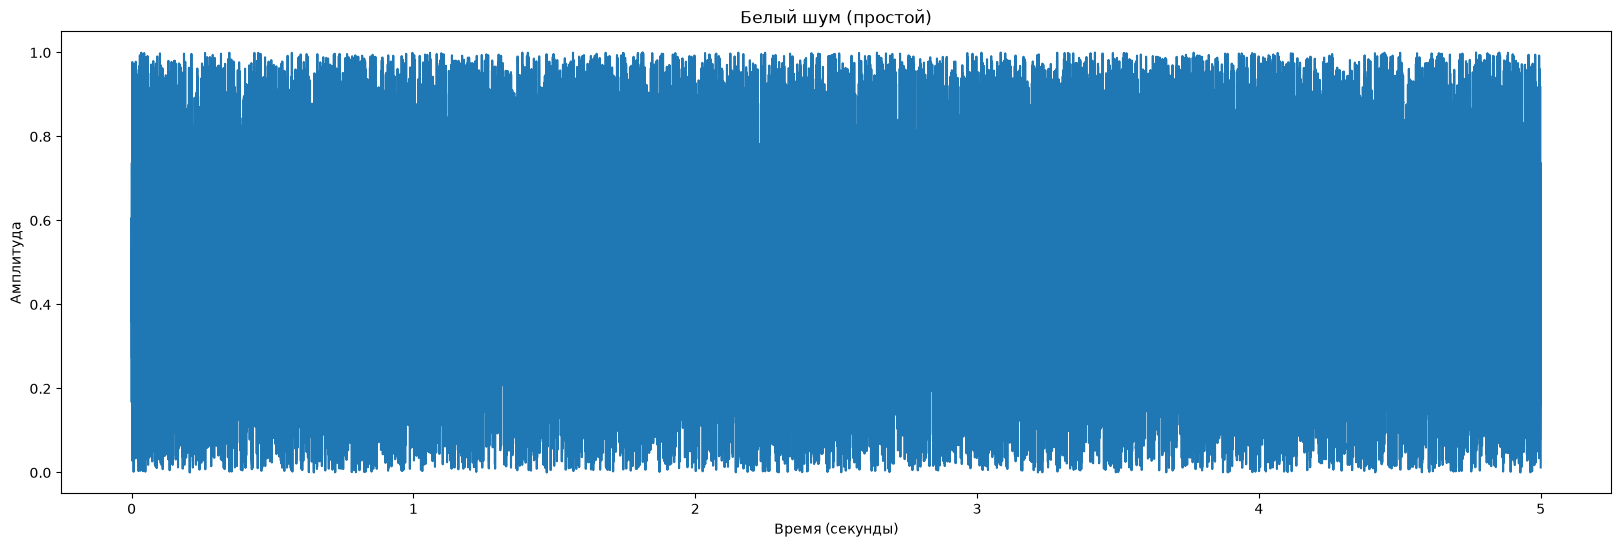

In [5]:
# отрисовываем, что получилось

# создаем временную шкалу. Считаем, что она начинается с 0, до окончания записи (duretion). 
# Между этими значениями равномерно заполняем ряд time_axis, чтобы в нем оказалось ровно столько элементов, сколько во временном ряду
time_axis = np.linspace(0, duration, len(white_noise_simple)) 

# заданем параметры полотна, на котором будем рисовать
plt.figure(figsize=(20, 6))  

# определяем, что будем отрисовывать. По x - time_axis, по y - white_noise_simple
plt.plot(time_axis, white_noise_simple)

# заголовки
plt.title('Белый шум (простой)')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

# команда на отрисовку
plt.show()


In [6]:
# генерируем гауссовский белый шум
# loc - медиана
# scale - стандартная девиация

white_noise_g = np.random.normal(loc = 0, scale = 1, size = num_samples)

print(white_noise_g)

[-1.03266978 -0.77071056  0.31089563 ... -0.43217189 -2.08189666
 -1.14345013]


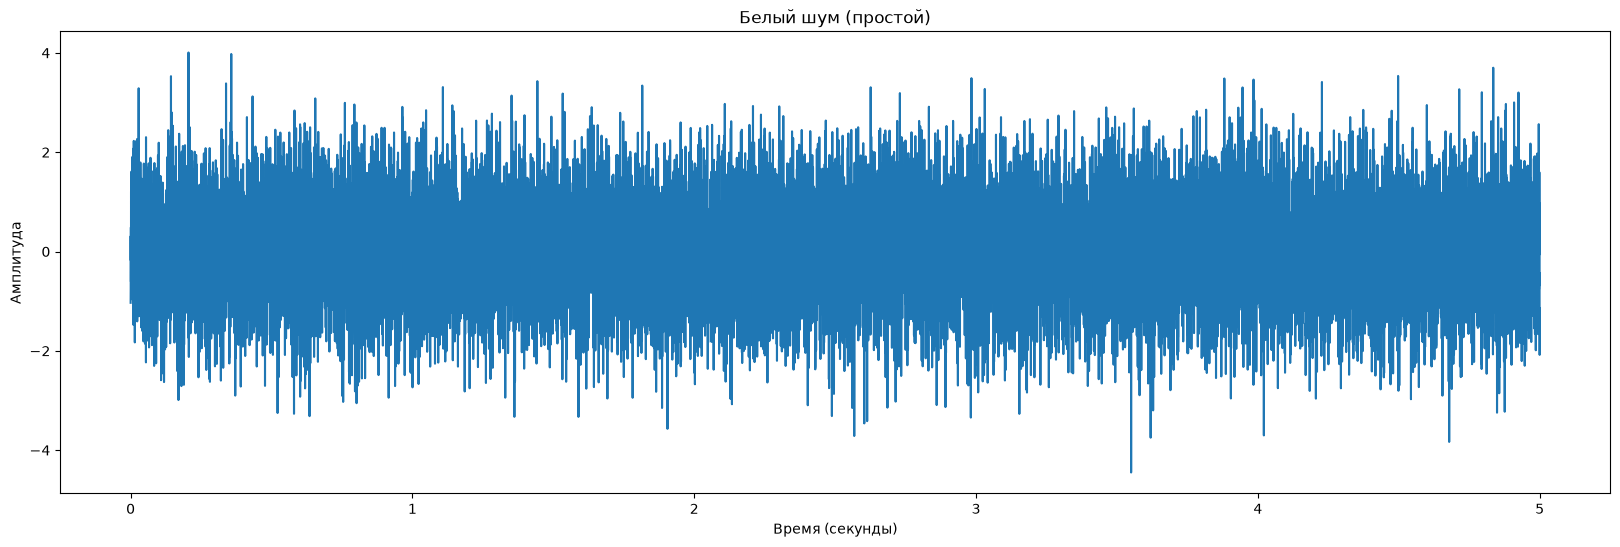

In [7]:
# отрисовываем, что получилось

# создаем временную шкалу. Считаем, что она начинается с 0, до окончания записи (duretion). 
# Между этими значениями равномерно заполняем ряд time_axis, чтобы в нем оказалось ровно столько элементов, сколько во временном ряду
time_axis = np.linspace(0, duration, len(white_noise_g)) 

# заданем параметры полотна, на котором будем рисовать
plt.figure(figsize=(20, 6))  

# определяем, что будем отрисовывать. По x - time_axis, по y - white_noise_simple
plt.plot(time_axis, white_noise_g)

# заголовки
plt.title('Белый шум (простой)')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

# команда на отрисовку
plt.show()


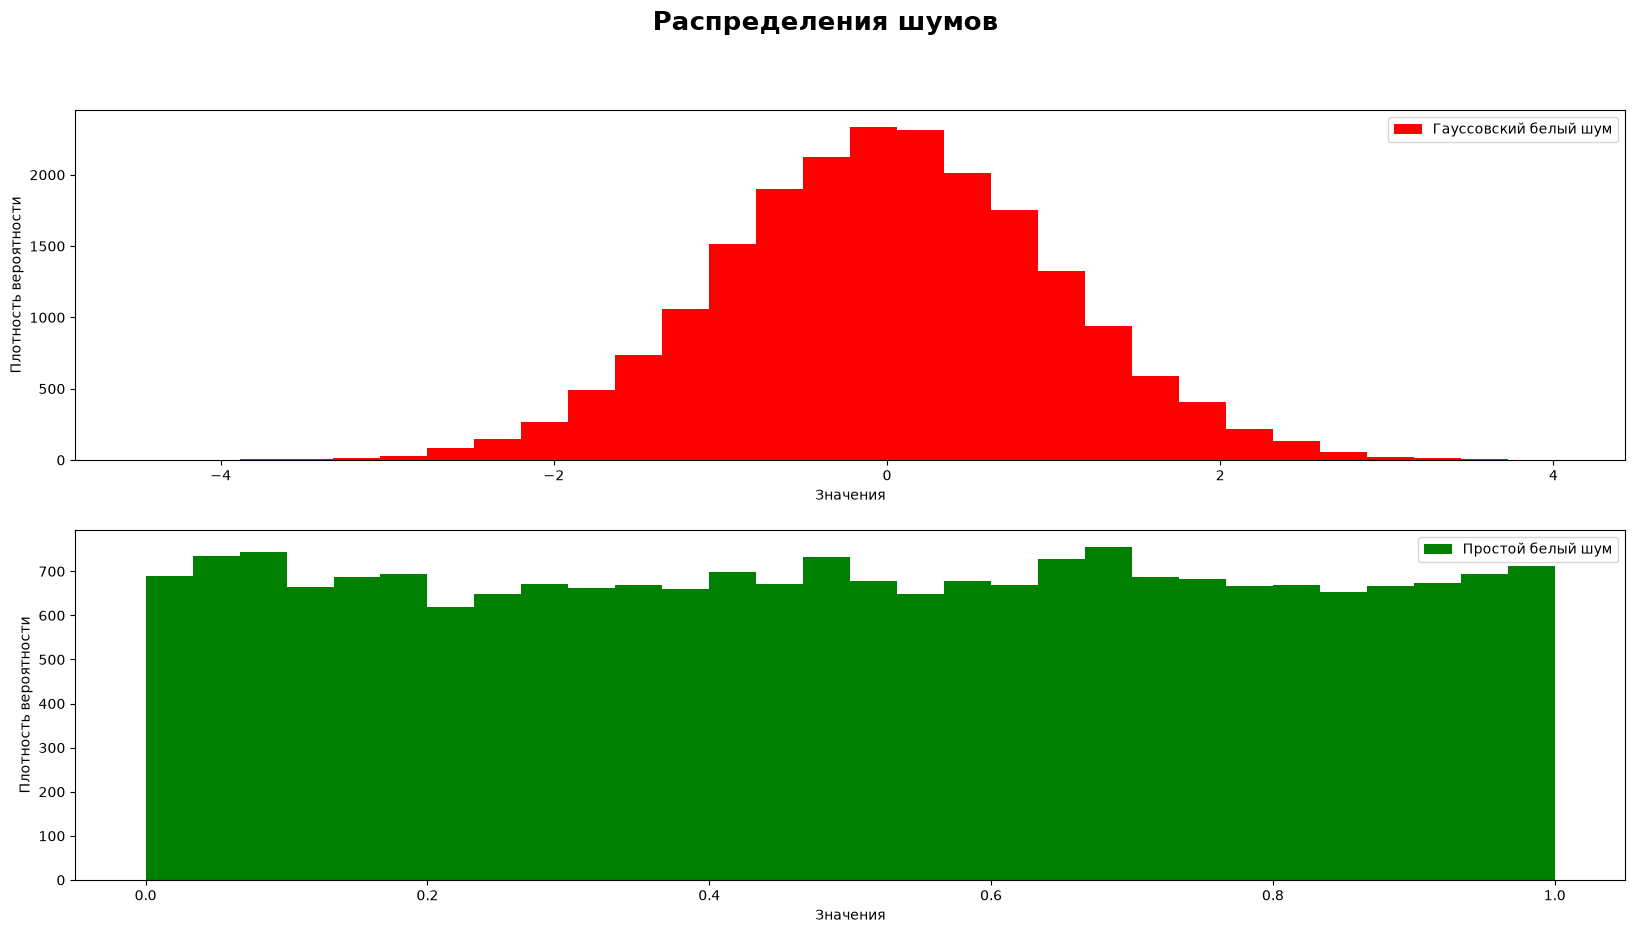

In [9]:
# Сравниваем распределения двух шумов
fig, ax = plt.subplots(2, 1, figsize=(20, 10))

# Общий заголовок
fig.suptitle('Распределения шумов', fontsize=19, fontweight='bold')

# 1. Грауссовский белый шум (сразу задаем label)
ax[0].hist(white_noise_g, color="red", bins=30, label="Гауссовский белый шум")
ax[0].set_xlabel('Значения')
ax[0].set_ylabel('Плотность вероятности')
ax[0].legend() # Включаем легенду для первого графика

# 2. Простой белый шум
ax[1].hist(white_noise_simple, color="green", bins=30, label="Простой белый шум")
ax[1].set_xlabel('Значения')
ax[1].set_ylabel('Плотность вероятности')
ax[1].legend() # Включаем легенду для второго графика

plt.show()

*Коричневый шум* - больше выделяются низкие частоты (имеют высокие амплитуды). Получается интегрирвание белого шума. 

Для этого нужно:
Создать белый гауссовкий шум с нулевой медианой.
Вычислить кумулятивную сумму полученного белого шума
От кумулятивной суммы отнять медианное значение
Отмасштабировать

На заметку:
Коричневый шум имеет ОГРОМНОЕ количество энергии на очень низких частотах и теоретически бесконечную энергию на частоте 0 Гц. Это, скорее всего, перегрузит любую разумную систему, поэтому вам, вероятно, понадобится коричневый шум с «ограниченной полосой пропускания». Самый простой способ сделать это — использовать фильтр верхних и нижних частот первого порядка вместо интегратора. Например, фильтр верхних частот на частоте 20 Гц и фильтр нижних частот на частоте 40 Гц.


In [10]:
# белый шум у нас уже есть. Давайте просто работать с ним

cumsum = np.cumsum(white_noise_g)  # кумулятивная сумма
brown_noise = cumsum - np.mean(cumsum)  # обнуляем медианное значение
scale_coeff =  np.max(np.abs(brown_noise))   # коэффициент для масшабирования, чтобы весь ряд находился между -1 и 1

brown_noise = brown_noise / scale_coeff  # Нормализация к [-1, 1] . Каждый элемент ряда делится на масштабирующий коэффициент

print(brown_noise)
print(white_noise_g)

[-0.56001864 -0.56525145 -0.5631406  ...  0.3021597   0.28802448
  0.28026093]
[-1.03266978 -0.77071056  0.31089563 ... -0.43217189 -2.08189666
 -1.14345013]


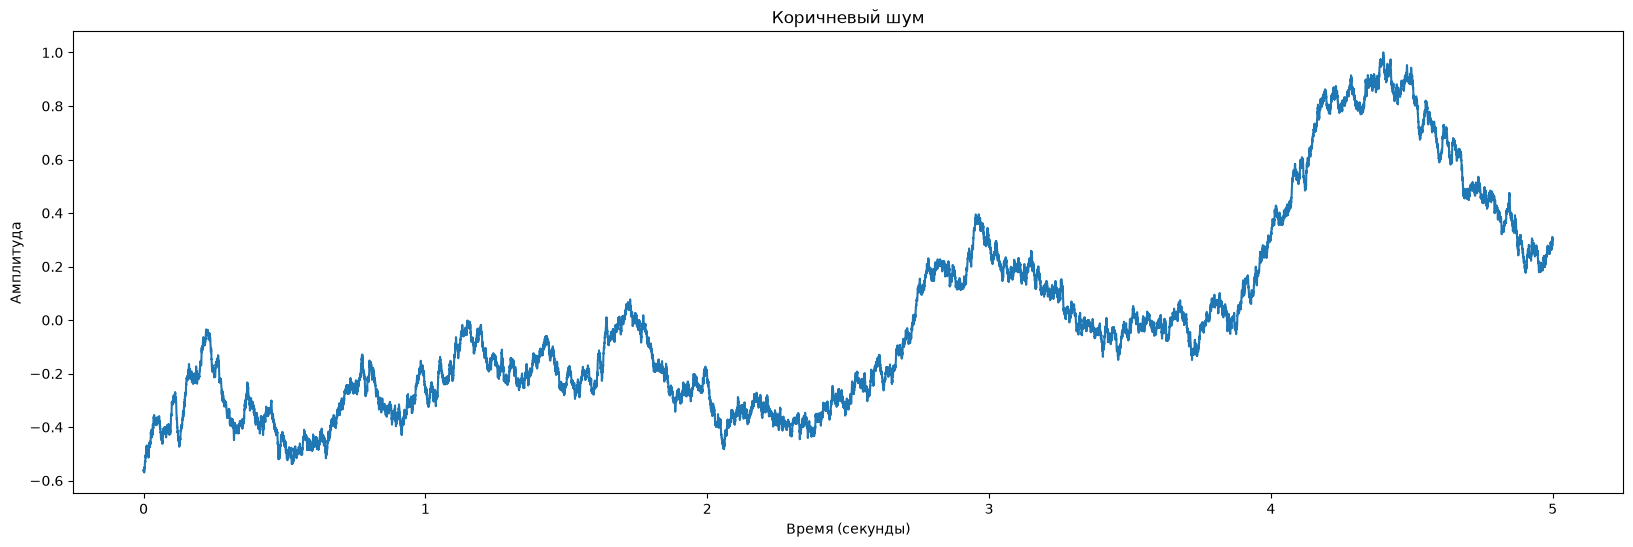

In [11]:
# отрисовываем, что получилось 
# создаем временную шкалу. Считаем, что она начинается с 0, до окончания записи (duretion). 
# Между этими значениями равномерно заполняем ряд time_axis, чтобы в нем оказалось ровно столько элементов, сколько во временном ряду
time_axis = np.linspace(0, duration, len(brown_noise)) 

# заданем параметры полотна, на котором будем рисовать
plt.figure(figsize=(20, 6))  

# определяем, что будем отрисовывать. По x - time_axis, по y - white_noise_simple
plt.plot(time_axis, brown_noise)

# заголовки
plt.title('Коричневый шум')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

# команда на отрисовку
plt.show()



In [12]:
# слушаем, что получилось
sd.play(brown_noise, sample_rate)
sd.wait()

*Розовый шум* или фликкер (мерцающий) шум - очень похож на белый. 

Розовый шум может быть сгенерирован путем первой генерации сигнала белого шума, преобразования его Фурье, затем деления амплитуд различных частотных составляющих на квадратный корень из частоты (в одном измерении) или на частоту (в двух измерениях) и т.д. Это эквивалентно пространственной фильтрации (свертке) сигнала белого шума с помощью фильтра от белого к розовому. Для сигнала длины N в одном измерении фильтр имеет следующий вид:

![Alt text](image-1.png)

Задание. Сгенерите розовый шум путем первой генерации сигнала белого шума, преобразования его Фурье, затем деления амплитуд различных частотных составляющих на квадратный корень из частоты.

Вам понадобятся функции np.fft.rfft , np.real , np.sqrt

In [13]:
duration = 5              
sample_rate = 4100        
num_samples = int(duration * sample_rate)

white_noise = np.random.normal(loc=0, scale=1, size=num_samples)

fft_white = np.fft.rfft(white_noise)

freqs = np.fft.rfftfreq(num_samples, d=1/sample_rate)
freqs_safe = np.copy(freqs)
freqs_safe[0] = freqs[1] if len(freqs) > 1 else 1

pink_fft = fft_white / np.sqrt(freqs_safe)
pink_noise = np.real(np.fft.irfft(pink_fft, n=num_samples))


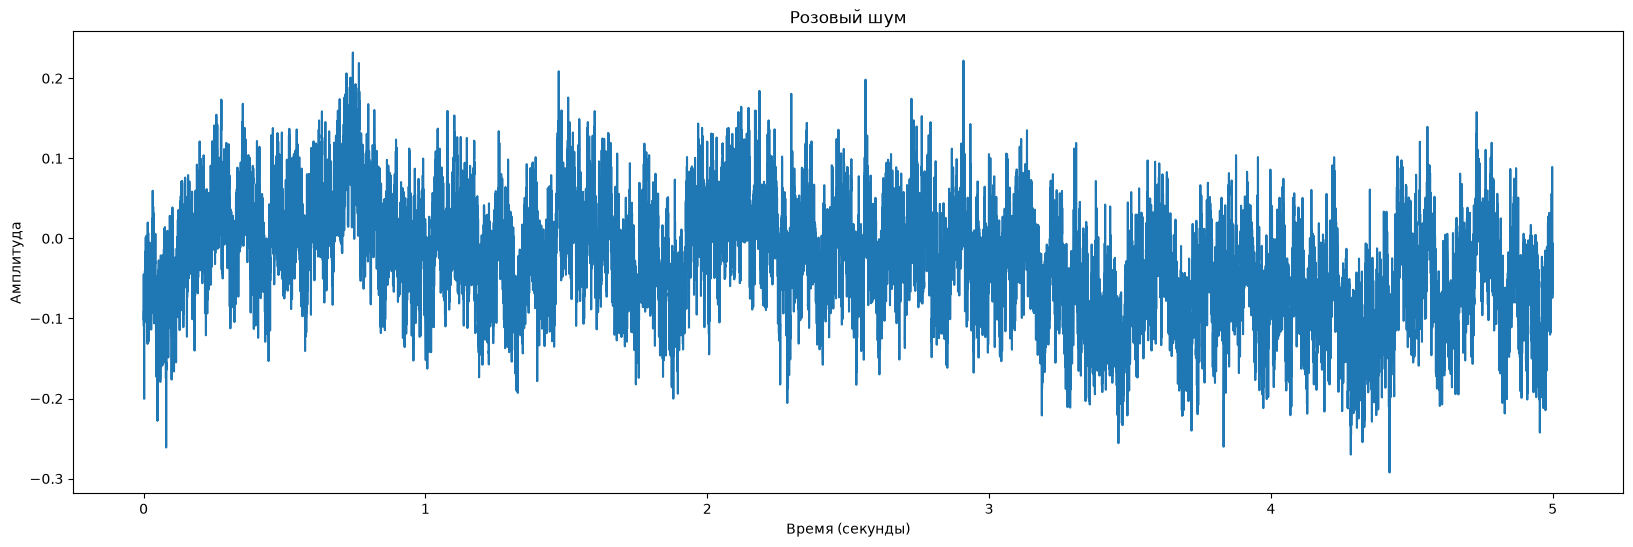

In [14]:
# отрисовываем, что получилось 
# создаем временную шкалу. Считаем, что она начинается с 0, до окончания записи (duretion). 
# Между этими значениями равномерно заполняем ряд time_axis, чтобы в нем оказалось ровно столько элементов, сколько во временном ряду
time_axis = np.linspace(0, duration, len(pink_noise)) 

# заданем параметры полотна, на котором будем рисовать
plt.figure(figsize=(20, 6))  

# определяем, что будем отрисовывать. По x - time_axis, по y - white_noise_simple
plt.plot(time_axis, pink_noise)

# заголовки
plt.title('Розовый шум')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')

# команда на отрисовку
plt.show()

*Черный шум*
Или тишина. Или шум на частотах, которые мы не слышим.

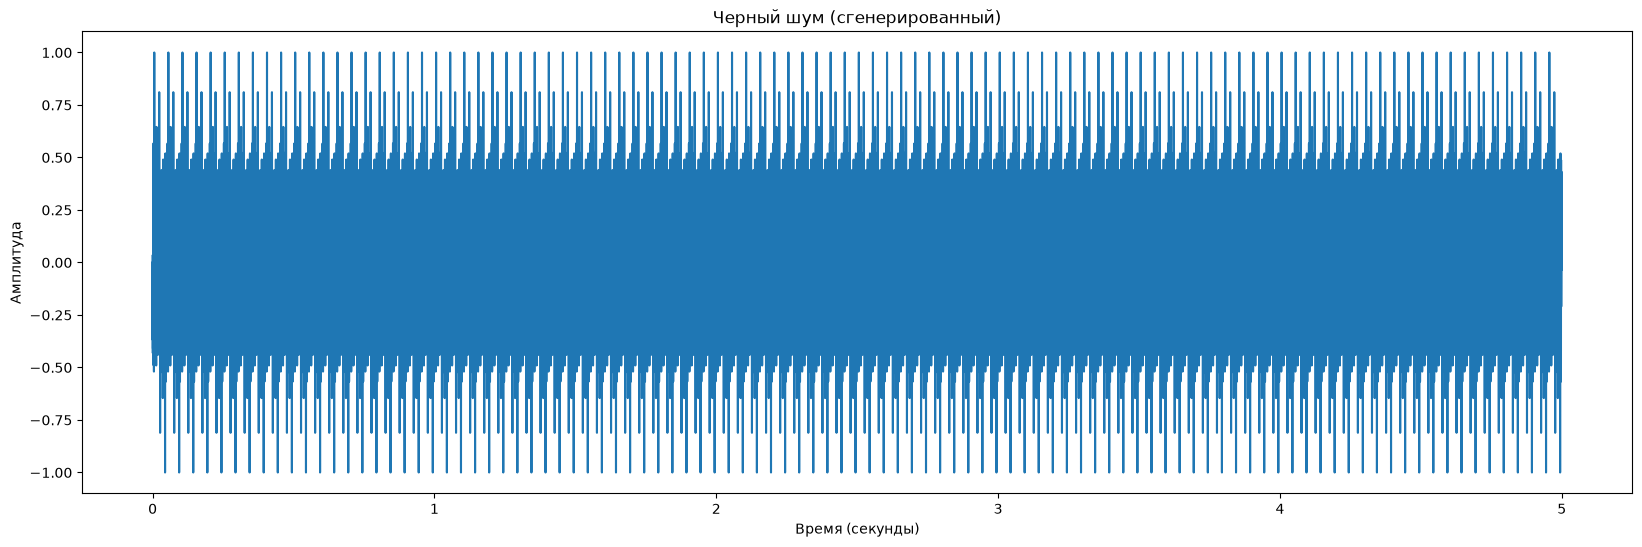

In [16]:
# Количество элементов в записи сигнала
num_samples = int(duration * sample_rate)
# Частоты в пределах частоты Найквиста (sample_rate / 2 = 2050 Гц)
freq1 = 20
freq2 = 2000 

# Частоты, на которых будем генерировать
num_frequencies = 100
frequencies = np.linspace(freq1, freq2, num_frequencies)

# Подготовили лист для записи сигнала
black_noise = np.zeros(num_samples)
time_axis = np.arange(num_samples) / sample_rate

# Амплитуды (случайные)
amplitudes = np.random.normal(0, 1, num_frequencies)

# Формируем сигнал
for i in range(num_frequencies):
    black_noise += amplitudes[i] * np.sin(2 * np.pi * frequencies[i] * time_axis)

# НОРМАЛИЗАЦИЯ (чтобы амплитуда была в пределах [-1, 1])
black_noise /= np.max(np.abs(black_noise))

# Визуализация (ВАЖНО: рисуем black_noise, а не amplitudes!)
plt.figure(figsize=(20, 6))
plt.plot(time_axis, black_noise)
plt.title('Черный шум (сгенерированный)')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')
plt.show()

Черный шум - как излучение абсолютно черного тела

Cпектральная плотность мощности излучения известна (непрерывную функцию частоты - f и температуры - T):

![Alt text](image.png)

kB - постоянная Больцмана
h  - Постоянная Планка
c  - скорость света

Поскольку выходная величина должна быть выражена в децибелах, чтобы иметь смысл для звука, мы просто используем логарифмическую шкалу и добавляем смещение (усиление), чтобы нормализовать пик до 0. Уравнение кривой эквалайзера равно:

![Alt text](image-2.png)

Еквалайзер применяем к белому шуму

In [18]:
import scipy

kb =  scipy.constants.k
h = scipy.constants.physical_constants['Planck constant'][0]
c = scipy.constants.c

print(kb)
print(h)
print(c)

T = 17*1/np.power(10, 9)  #Температура 17 нанокельвинов
G = 10

coef1 = 2*h/(c*c*T*T*T)
coef2 = h/(kb*T)

freq1 = 1000

# количество элементов в записи сигнала. Для 17 нанокельвинов полоса пропускания шума будет от 1Гц до 12 кГц
num_samples = int(duration * freq1)


# Частоты, на которых будем генерировать

black_noise = np.zeros(num_samples)   # подготовили лист для записи сигнала
time_axis = np.arange(num_samples) / sample_rate   # задали временную ось



black_noise = np.zeros(num_samples)
time_axis = np.arange(num_samples) / sample_rate
eq = 10 * np.log(coef1*np.power(freq1,3)/(np.exp(coef2*freq1)-1)) + 10 # эквалайзер

white_noise_g = np.random.normal(loc = 0, scale = 1, size = num_samples) # опять белый шум

black_noise = white_noise_g + eq # применяем преобразование к белому шуму

black_noise /= np.max(np.abs(black_noise))  # Нормализация амплитуды к [-1, 1]

                                         

1.380649e-23
6.62607015e-34
299792458.0


In [19]:
# так звучит черное тело

sd.play(black_noise, freq1)
sd.wait()

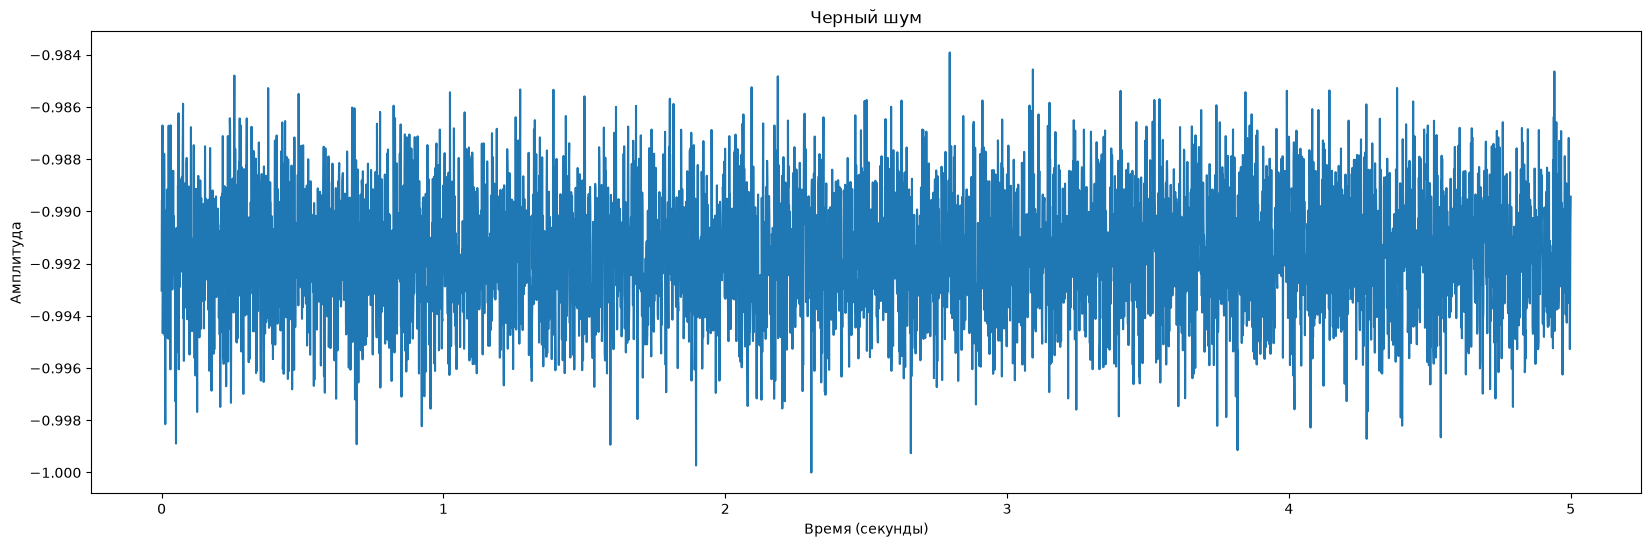

In [20]:
# Визуализация
time_axis = np.linspace(0, duration, len(black_noise))
plt.figure(figsize=(20, 6))
plt.plot(time_axis, black_noise)
plt.title('Черный шум')
plt.xlabel('Время (секунды)')
plt.ylabel('Амплитуда')
plt.show()

## Генерация временных рядов

Этот код создает пример временного ряда, представленного как синусоида с добавлением случайного шума. Это просто пример, можно изменить генерацию данных в соответствии с вашими потребностями.

In [21]:
duration = 5  # Продолжительность в секундах
sample_rate = 4100  # Частота дискретизации в Гц

num_points = duration*sample_rate  # количество точек

time_points = np.linspace(0, duration, num_points)  # Создаем равномерные временные точки от 0 до 5 секунд

white_noise_base = np.random.normal(0,1,size=num_points)  # Генерим белый шум

values = 10*np.sin(4*time_points*np.pi) # вычисляем амплитуды сигнала по синусоидальному закону

values_noise = values + white_noise_base # зашумляем сигнал



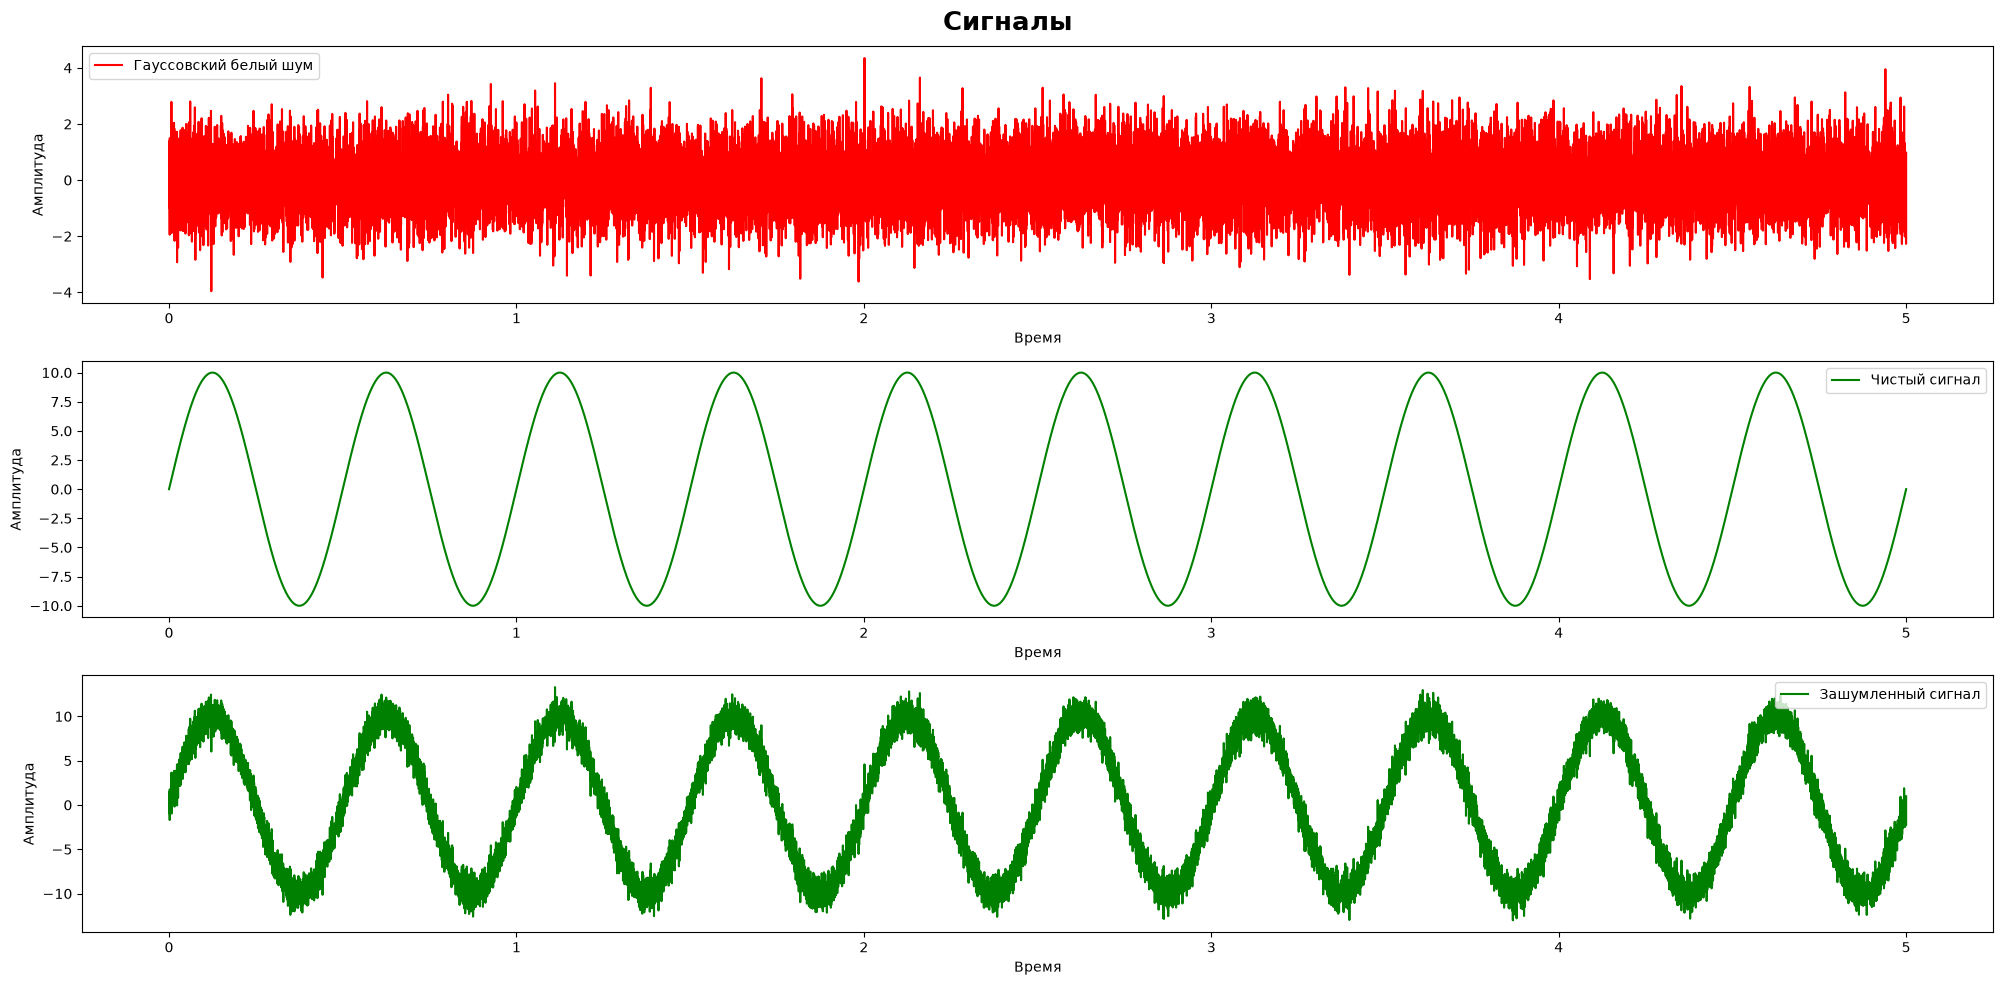

In [23]:
# Отрисовываем
fig, ax = plt.subplots(3, 1, figsize=(20, 10))

# Общий заголовок для всей картинки
fig.suptitle('Сигналы', fontsize=19, fontweight='bold')

# 1. Грауссовский белый шум (добавляем label прямо в plot)
ax[0].plot(time_points, white_noise_base, color="red", label="Гауссовский белый шум")
ax[0].set_xlabel('Время')
ax[0].set_ylabel('Амплитуда')
ax[0].legend() # Включаем легенду локально для этого графика

# 2. Чистый сигнал
ax[1].plot(time_points, values, color="green", label="Чистый сигнал")
ax[1].set_xlabel('Время')
ax[1].set_ylabel('Амплитуда')
ax[1].legend()

# 3. Зашумленный сигнал
ax[2].plot(time_points, values_noise, color="green", label="Зашумленный сигнал")
ax[2].set_xlabel('Время')
ax[2].set_ylabel('Амплитуда')
ax[2].legend()

plt.tight_layout() # Чтобы графики не наезжали друг на друга
plt.show()

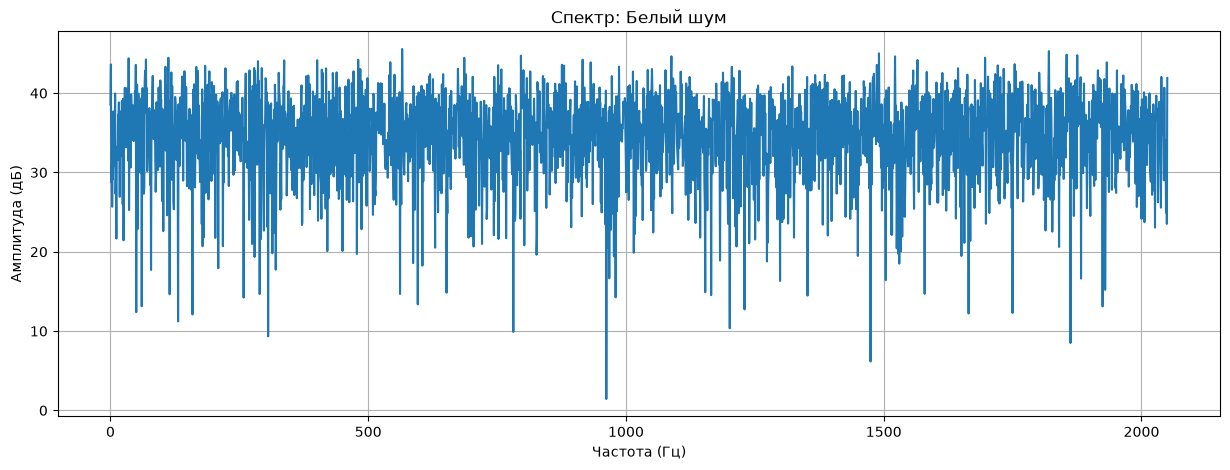

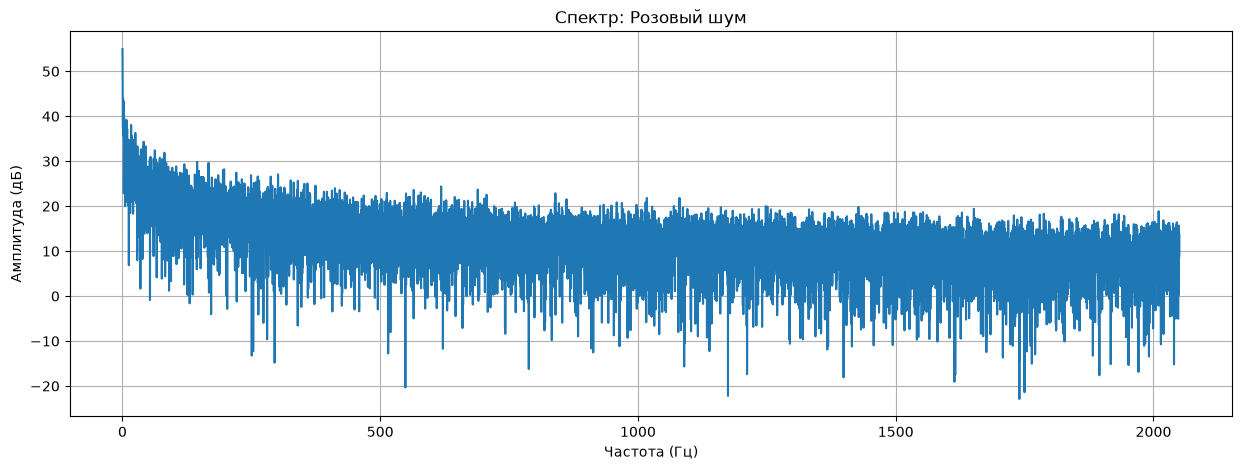

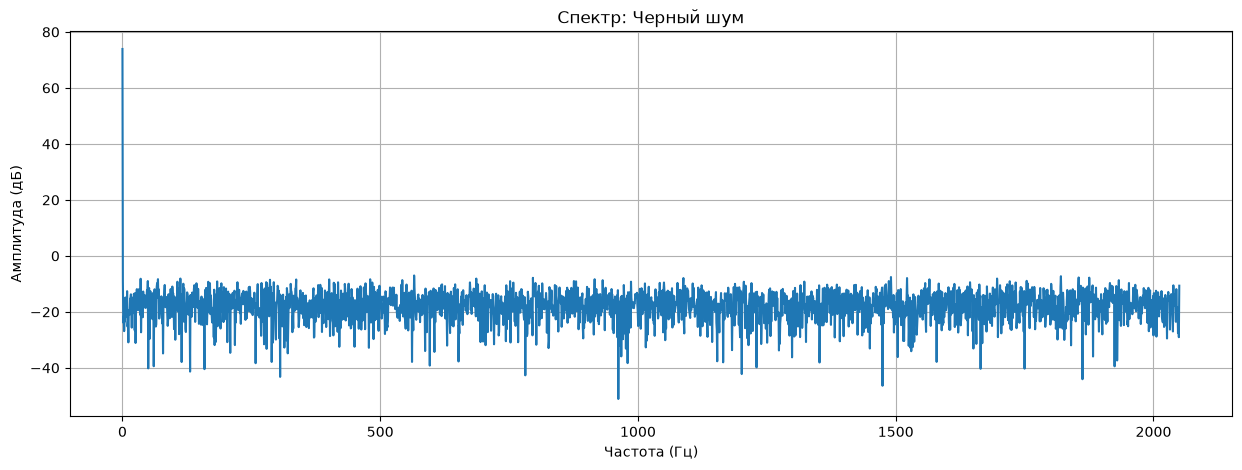

In [24]:
def plot_spectrum(signal, sample_rate, title):
    N = len(signal)
    # Быстрое преобразование Фурье
    yf = np.fft.rfft(signal)
    xf = np.fft.rfftfreq(N, 1 / sample_rate)
    
    plt.figure(figsize=(15, 5))
    # Строим спектр в логарифмическом масштабе (в дБ)
    plt.plot(xf, 20 * np.log10(np.abs(yf)))
    plt.title(f'Спектр: {title}')
    plt.xlabel('Частота (Гц)')
    plt.ylabel('Амплитуда (дБ)')
    plt.grid(True)
    plt.show()

# Строим спектры для наших шумов
plot_spectrum(white_noise_g, sample_rate, "Белый шум")
plot_spectrum(pink_noise, sample_rate, "Розовый шум")
plot_spectrum(black_noise, sample_rate, "Черный шум")